# Gradient Descent: Complete Guide

Gradient Descent is an optimization algorithm used to minimize the cost function by iteratively moving towards the minimum.

## Topics Covered:
1. **What is Gradient Descent?** - Intuition and core concepts
2. **Batch Gradient Descent** - Uses all training data
3. **Stochastic Gradient Descent (SGD)** - Uses one sample at a time
4. **Mini-Batch Gradient Descent** - Uses small batches
5. **Learning Rate** - Importance and tuning
6. **Momentum-based Optimization**
7. **Adam Optimizer** - Adaptive learning rates
8. **Visual Comparison** of all variants

## 1. Introduction to Gradient Descent

### Core Concept
Gradient Descent is an iterative optimization algorithm used to find the minimum of a function by taking steps proportional to the negative of the gradient.

### Key Components:
- **Cost Function (J(θ))**: Measures the error of predictions
- **Gradient (∇J(θ))**: Direction of steepest ascent
- **Learning Rate (α)**: Step size for each iteration
- **Update Rule**: θ = θ - α * ∇J(θ)

### Intuition
Imagine being on a mountain and wanting to reach the valley:
- Look around to find the steepest downward direction (gradient)
- Take a step in that direction (learning rate determines step size)
- Repeat until you reach the bottom (minimum)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import SGDRegressor
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 2. Simple Gradient Descent Implementation

Let's implement gradient descent for a simple linear regression problem.

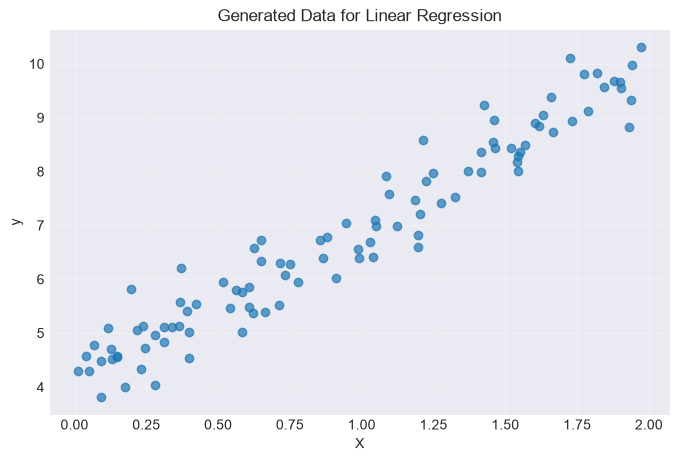

In [2]:
# Generate synthetic data
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1) * 0.5

# Visualize data
plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.7)
plt.xlabel('X')
plt.ylabel('y')
plt.title('Generated Data for Linear Regression')
plt.grid(True, alpha=0.3)
plt.show()

=== Batch Gradient Descent Results ===
Theta (intercept, slope): [3.82035054 3.13863651]
Final cost: 0.1137


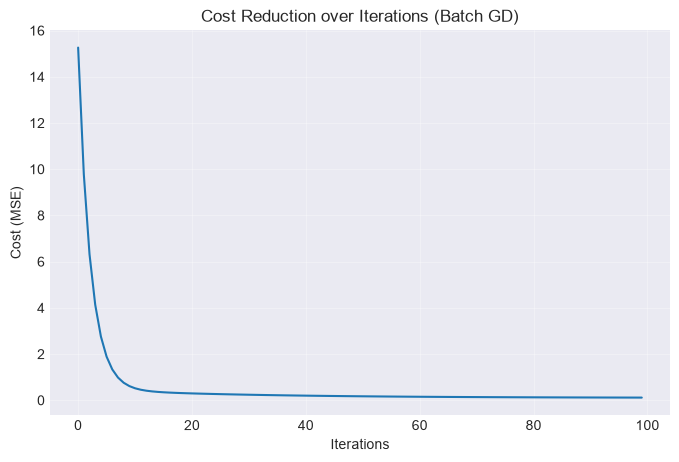

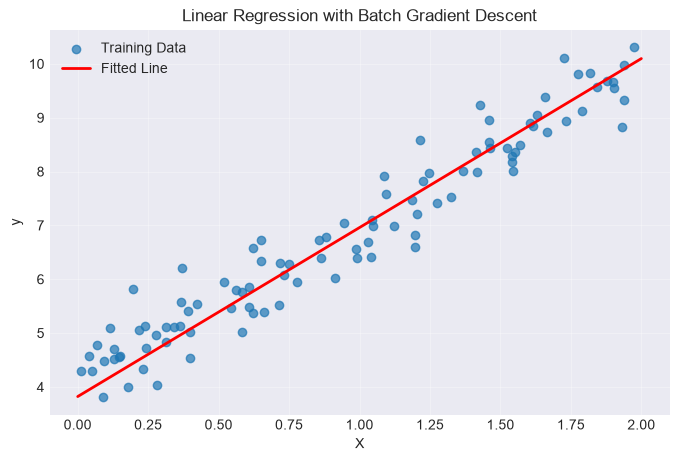

In [3]:
# Add bias term (x0 = 1) to X
X_b = np.c_[np.ones((X.shape[0], 1)), X]  # Add column of ones for bias

# Batch Gradient Descent implementation
def batch_gradient_descent(X, y, learning_rate=0.1, n_iterations=1000):
    """
    Batch Gradient Descent for linear regression
    
    Parameters:
    X: feature matrix with bias term
    y: target values
    learning_rate: step size for updates
    n_iterations: number of iterations
    
    Returns:
    theta: optimized parameters
    history: cost history for visualization
    """
    m = len(y)  # Number of training examples
    theta = np.random.randn(X.shape[1], 1)  # Random initialization
    cost_history = []
    
    for iteration in range(n_iterations):
        # Calculate predictions
        predictions = X.dot(theta)
        
        # Calculate errors
        errors = predictions - y
        
        # Calculate gradient (average gradient over all samples)
        gradient = (1/m) * X.T.dot(errors)
        
        # Update parameters
        theta = theta - learning_rate * gradient
        
        # Calculate and store cost (MSE)
        cost = (1/(2*m)) * np.sum(errors ** 2)
        cost_history.append(cost)
    
    return theta, cost_history

# Run Batch Gradient Descent
theta_bgd, cost_history_bgd = batch_gradient_descent(X_b, y, learning_rate=0.1, n_iterations=100)

print("=== Batch Gradient Descent Results ===")
print(f"Theta (intercept, slope): {theta_bgd.flatten()}")
print(f"Final cost: {cost_history_bgd[-1]:.4f}")

# Plot the cost over iterations
plt.figure(figsize=(8, 5))
plt.plot(cost_history_bgd)
plt.xlabel('Iterations')
plt.ylabel('Cost (MSE)')
plt.title('Cost Reduction over Iterations (Batch GD)')
plt.grid(True, alpha=0.3)
plt.show()

# Visualize the fitted line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.7, label='Training Data')
X_line = np.linspace(0, 2, 100).reshape(-1, 1)
X_line_b = np.c_[np.ones((100, 1)), X_line]
y_line = X_line_b.dot(theta_bgd)
plt.plot(X_line, y_line, 'r-', label='Fitted Line', linewidth=2)
plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Regression with Batch Gradient Descent')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3. Types of Gradient Descent

### 3.1 Batch Gradient Descent

**Definition**: Uses the entire training dataset to compute the gradient of the cost function.

**Update Rule**: θ = θ - α * (1/m) * Σ(ŷᵢ - yᵢ) * xᵢ

**Pros**:
- Stable convergence
- Accurate gradient estimate
- Good for convex functions

**Cons**:
- Slow for large datasets
- Memory intensive
- Can get stuck in local minima

In [4]:
# Detailed Batch Gradient Descent implementation with visualization
def batch_gd_detailed(X, y, learning_rate=0.1, n_iterations=50):
    """Detailed implementation with step-by-step tracking"""
    m = len(y)
    theta = np.random.randn(X.shape[1], 1)
    
    # Track progress for visualization
    theta_path = [theta.copy()]
    cost_path = []
    
    print("Batch Gradient Descent Progress:")
    for i in range(n_iterations):
        predictions = X.dot(theta)
        errors = predictions - y
        gradient = (1/m) * X.T.dot(errors)
        theta = theta - learning_rate * gradient
        
        cost = (1/(2*m)) * np.sum(errors ** 2)
        theta_path.append(theta.copy())
        cost_path.append(cost)
        
        if i % 10 == 0:
            print(f"Iteration {i}: Cost = {cost:.4f}, θ = {theta.flatten()}")
    
    print(f"Final (Iteration {n_iterations-1}): Cost = {cost_path[-1]:.4f}")
    return theta, theta_path, cost_path

theta_bgd_detailed, theta_path, cost_path = batch_gd_detailed(X_b, y, learning_rate=0.1, n_iterations=100)

Batch Gradient Descent Progress:
Iteration 0: Cost = 10.3536, θ = [0.18806905 3.15167379]
Iteration 10: Cost = 0.7978, θ = [1.98328646 4.44458308]
Iteration 20: Cost = 0.5313, θ = [2.43410936 4.33133312]
Iteration 30: Cost = 0.4058, θ = [2.70891737 4.11687626]
Iteration 40: Cost = 0.3174, θ = [2.93009276 3.92437943]
Iteration 50: Cost = 0.2546, θ = [3.1154436  3.76100071]
Iteration 60: Cost = 0.2100, θ = [3.27153311 3.62320947]
Iteration 70: Cost = 0.1784, θ = [3.40305647 3.50708419]
Iteration 80: Cost = 0.1559, θ = [3.51388752 3.40922667]
Iteration 90: Cost = 0.1399, θ = [3.60728248 3.32676402]
Final (Iteration 99): Cost = 0.1296


### 3.2 Stochastic Gradient Descent (SGD)

**Definition**: Updates parameters using one random sample at a time.

**Update Rule**: θ = θ - α * (ŷᵢ - yᵢ) * xᵢ

**Pros**:
- Very fast for large datasets
- Can escape local minima
- Online learning possible

**Cons**:
- Noisy updates
- Slower convergence
- Needs careful learning rate scheduling

Stochastic Gradient Descent Progress:
Epoch 0: Cost = 0.5207
Epoch 10: Cost = 0.1009
Epoch 20: Cost = 0.1010
Epoch 30: Cost = 0.1008
Epoch 40: Cost = 0.1009
Epoch 50: Cost = 0.1010
Epoch 60: Cost = 0.1008
Epoch 70: Cost = 0.1010
Epoch 80: Cost = 0.1010
Epoch 90: Cost = 0.1014
Final (Epoch 99): Cost = 0.1009

SGD Final Theta: [4.10123381 2.87809579]


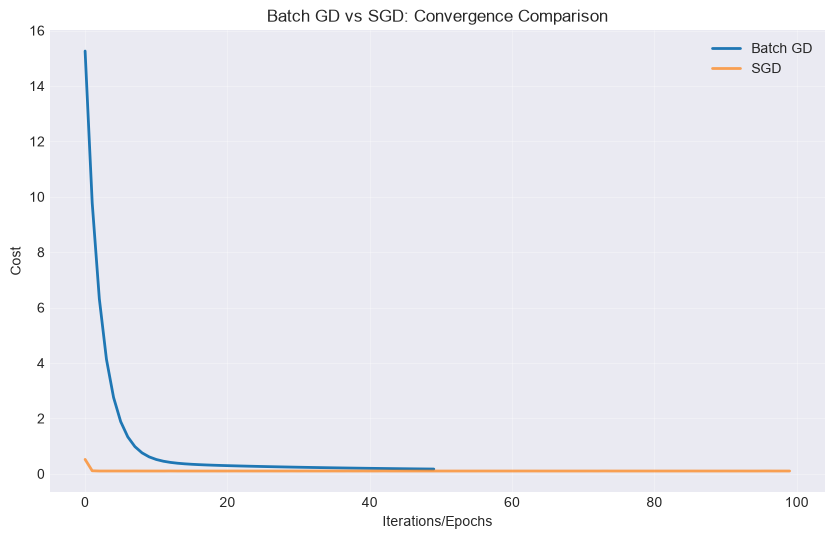

In [5]:
def stochastic_gradient_descent(X, y, learning_rate=0.01, n_epochs=50):
    """
    Stochastic Gradient Descent implementation
    
    Parameters:
    X: feature matrix with bias term
    y: target values
    learning_rate: step size
    n_epochs: number of passes through the data
    """
    m = len(y)
    theta = np.random.randn(X.shape[1], 1)
    cost_history = []
    theta_history = []
    
    print("Stochastic Gradient Descent Progress:")
    for epoch in range(n_epochs):
        # Shuffle data
        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]
        
        for i in range(m):
            # Take one sample
            xi = X_shuffled[i:i+1]
            yi = y_shuffled[i:i+1]
            
            # Calculate prediction
            prediction = xi.dot(theta)
            error = prediction - yi
            
            # Update using gradient from single sample
            gradient = xi.T.dot(error)
            theta = theta - learning_rate * gradient
        
        # Calculate cost after each epoch
        predictions = X.dot(theta)
        errors = predictions - y
        cost = (1/(2*m)) * np.sum(errors ** 2)
        cost_history.append(cost)
        theta_history.append(theta.copy())
        
        if epoch % 10 == 0:
            print(f"Epoch {epoch}: Cost = {cost:.4f}")
    
    print(f"Final (Epoch {n_epochs-1}): Cost = {cost_history[-1]:.4f}")
    return theta, cost_history, theta_history

# Run SGD
theta_sgd, cost_history_sgd, _ = stochastic_gradient_descent(X_b, y, learning_rate=0.01, n_epochs=100)

print(f"\nSGD Final Theta: {theta_sgd.flatten()}")

# Compare Batch GD and SGD
plt.figure(figsize=(10, 6))
plt.plot(cost_history_bgd[:50], label='Batch GD', linewidth=2)
plt.plot(cost_history_sgd, label='SGD', linewidth=2, alpha=0.7)
plt.xlabel('Iterations/Epochs')
plt.ylabel('Cost')
plt.title('Batch GD vs SGD: Convergence Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 3.3 Mini-Batch Gradient Descent

**Definition**: Uses a small batch of random samples to compute the gradient.

**Update Rule**: θ = θ - α * (1/batch_size) * Σ(ŷᵢ - yᵢ) * xᵢ

**Pros**:
- Best of both worlds
- More stable than SGD
- Faster than Batch GD
- GPU friendly

**Cons**:
- Need to choose batch size
- Still some noise in updates

Mini-Batch Gradient Descent Progress:
Epoch 0: Cost = 1.9673
Epoch 10: Cost = 0.1443
Epoch 20: Cost = 0.1088
Epoch 30: Cost = 0.1022
Epoch 40: Cost = 0.1012
Epoch 50: Cost = 0.1010
Epoch 60: Cost = 0.1010
Epoch 70: Cost = 0.1009
Epoch 80: Cost = 0.1010
Epoch 90: Cost = 0.1009
Final (Epoch 99): Cost = 0.1009

Mini-Batch GD Final Theta: [4.11080864 2.89056489]


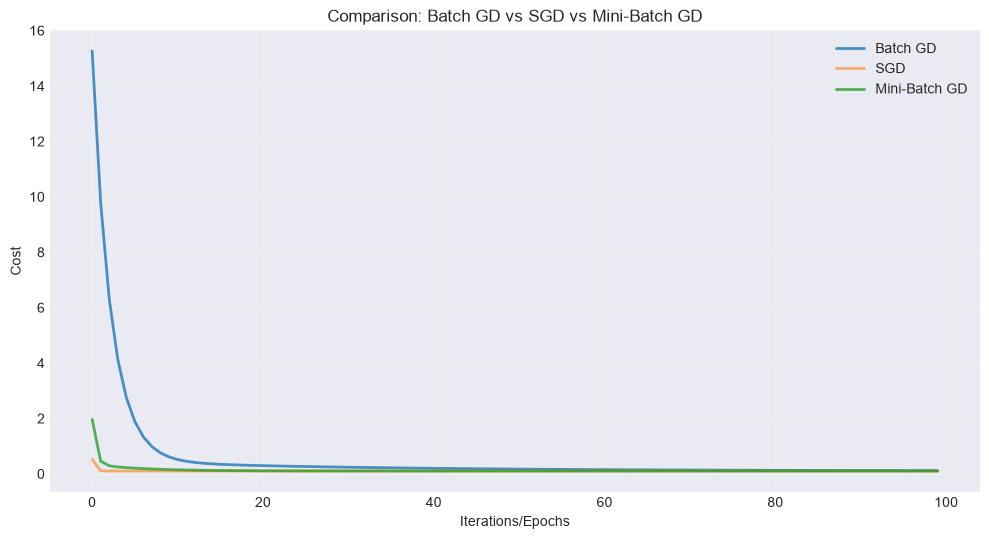

In [6]:
def mini_batch_gradient_descent(X, y, learning_rate=0.1, batch_size=20, n_epochs=100):
    """
    Mini-Batch Gradient Descent implementation
    
    Parameters:
    X: feature matrix with bias term
    y: target values
    learning_rate: step size
    batch_size: number of samples per batch
    n_epochs: number of passes through the data
    """
    m = len(y)
    theta = np.random.randn(X.shape[1], 1)
    cost_history = []
    
    print("Mini-Batch Gradient Descent Progress:")
    for epoch in range(n_epochs):
        # Shuffle data
        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]
        
        for i in range(0, m, batch_size):
            # Get mini-batch
            X_batch = X_shuffled[i:i+batch_size]
            y_batch = y_shuffled[i:i+batch_size]
            
            # Calculate predictions
            predictions = X_batch.dot(theta)
            errors = predictions - y_batch
            
            # Update using batch gradient
            gradient = (1/batch_size) * X_batch.T.dot(errors)
            theta = theta - learning_rate * gradient
        
        # Calculate cost after each epoch
        predictions = X.dot(theta)
        errors = predictions - y
        cost = (1/(2*m)) * np.sum(errors ** 2)
        cost_history.append(cost)
        
        if epoch % 10 == 0:
            print(f"Epoch {epoch}: Cost = {cost:.4f}")
    
    print(f"Final (Epoch {n_epochs-1}): Cost = {cost_history[-1]:.4f}")
    return theta, cost_history

# Run Mini-Batch GD
theta_mbgd, cost_history_mbgd = mini_batch_gradient_descent(
    X_b, y, learning_rate=0.1, batch_size=20, n_epochs=100
)

print(f"\nMini-Batch GD Final Theta: {theta_mbgd.flatten()}")

# Compare all three variants
plt.figure(figsize=(12, 6))
plt.plot(cost_history_bgd, label='Batch GD', linewidth=2, alpha=0.8)
plt.plot(cost_history_sgd, label='SGD', linewidth=2, alpha=0.6)
plt.plot(cost_history_mbgd, label='Mini-Batch GD', linewidth=2, alpha=0.8)
plt.xlabel('Iterations/Epochs')
plt.ylabel('Cost')
plt.title('Comparison: Batch GD vs SGD vs Mini-Batch GD')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 4. Learning Rate and Its Importance

The learning rate (α) determines the step size in each iteration.

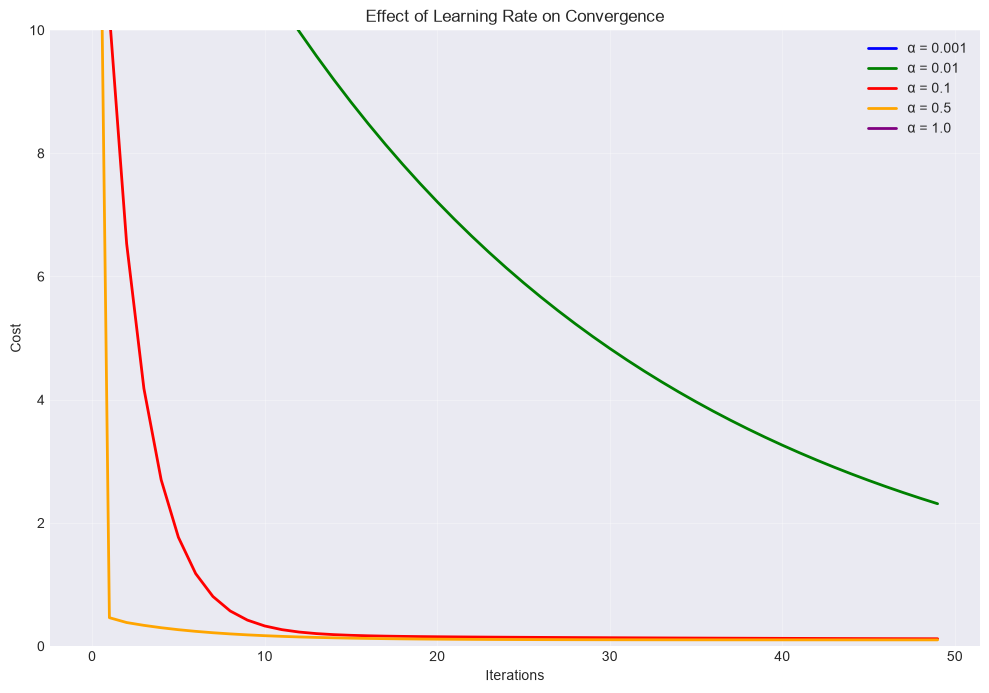


Key Takeaways on Learning Rate:
- α too small: Slow convergence, may get stuck
- α too large: May overshoot and diverge
- Optimal α: Allows steady convergence to minimum
- Learning rate scheduling can help: decrease α over time



In [7]:
# Demonstrate different learning rates
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
colors = ['blue', 'green', 'red', 'orange', 'purple']

plt.figure(figsize=(12, 8))

for lr, color in zip(learning_rates, colors):
    try:
        _, cost_history = batch_gradient_descent(X_b, y, learning_rate=lr, n_iterations=50)
        plt.plot(cost_history, label=f'α = {lr}', color=color, linewidth=2)
    except:
        print(f"Learning rate {lr} caused divergence")

plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Effect of Learning Rate on Convergence')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 10)  # Limit y-axis for better visualization
plt.show()

print("""
Key Takeaways on Learning Rate:
- α too small: Slow convergence, may get stuck
- α too large: May overshoot and diverge
- Optimal α: Allows steady convergence to minimum
- Learning rate scheduling can help: decrease α over time
""")

## 5. Advanced Optimization Techniques

### 5.1 Gradient Descent with Momentum

Momentum helps accelerate gradient descent in the right direction and dampens oscillations.

**Update Rules**:
- v = β * v + α * ∇J(θ)
- θ = θ - v

where β is the momentum parameter (typically 0.9)

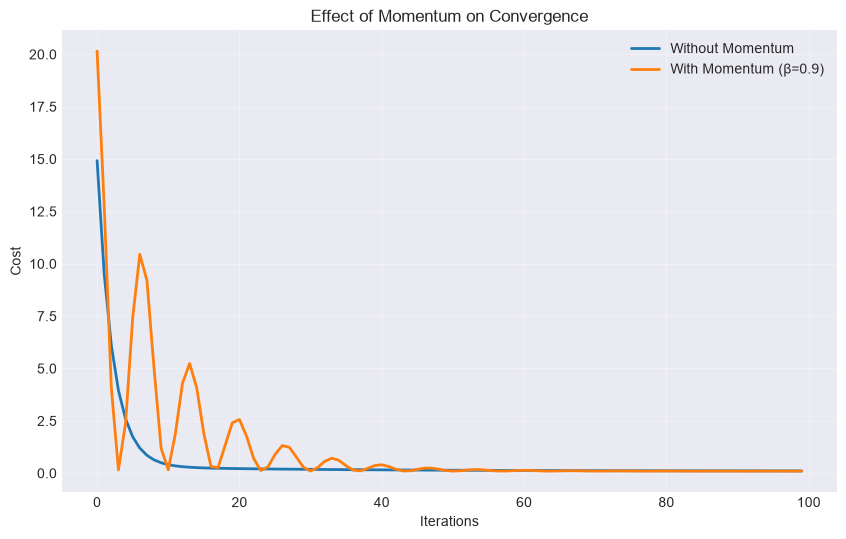

In [8]:
def gradient_descent_with_momentum(X, y, learning_rate=0.1, momentum=0.9, n_iterations=100):
    """
    Gradient Descent with Momentum
    """
    m = len(y)
    theta = np.random.randn(X.shape[1], 1)
    velocity = np.zeros((X.shape[1], 1))
    cost_history = []
    
    for iteration in range(n_iterations):
        predictions = X.dot(theta)
        errors = predictions - y
        gradient = (1/m) * X.T.dot(errors)
        
        # Update velocity with momentum
        velocity = momentum * velocity + learning_rate * gradient
        theta = theta - velocity
        
        cost = (1/(2*m)) * np.sum(errors ** 2)
        cost_history.append(cost)
    
    return theta, cost_history

# Compare with and without momentum
theta_no_momentum, cost_no_momentum = batch_gradient_descent(X_b, y, learning_rate=0.1, n_iterations=100)
theta_momentum, cost_momentum = gradient_descent_with_momentum(X_b, y, learning_rate=0.1, momentum=0.9, n_iterations=100)

plt.figure(figsize=(10, 6))
plt.plot(cost_no_momentum, label='Without Momentum', linewidth=2)
plt.plot(cost_momentum, label='With Momentum (β=0.9)', linewidth=2)
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Effect of Momentum on Convergence')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 5.2 Adam Optimizer

Adam (Adaptive Moment Estimation) combines momentum with adaptive learning rates.

**Key Features**:
- Maintains per-parameter learning rates
- Combines momentum and RMSprop
- Bias correction for initial steps
- Works well in practice

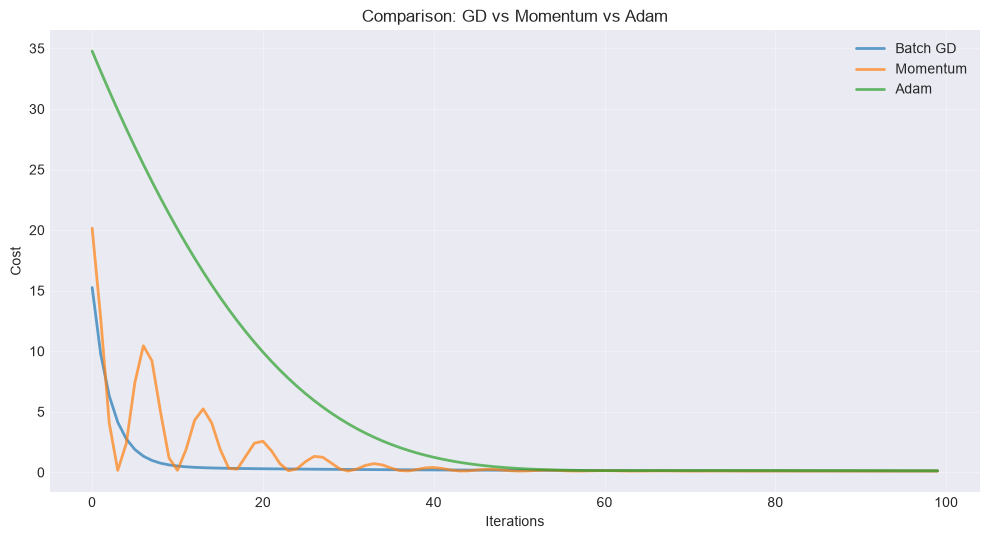

Batch GD Final Theta: [3.82035054 3.13863651]
Momentum Final Theta: [4.12002616 2.90382272]
Adam Final Theta: [3.71734236 3.28497133]


In [9]:
def adam_optimizer(X, y, learning_rate=0.001, beta1=0.9, beta2=0.999, epsilon=1e-8, n_iterations=100):
    """
    Adam Optimizer implementation
    """
    m = len(y)
    theta = np.random.randn(X.shape[1], 1)
    
    # Initialize moment estimates
    m_t = np.zeros((X.shape[1], 1))  # First moment (mean of gradients)
    v_t = np.zeros((X.shape[1], 1))  # Second moment (variance of gradients)
    
    cost_history = []
    
    for t in range(1, n_iterations + 1):
        predictions = X.dot(theta)
        errors = predictions - y
        gradient = (1/m) * X.T.dot(errors)
        
        # Update biased first moment estimate
        m_t = beta1 * m_t + (1 - beta1) * gradient
        
        # Update biased second moment estimate
        v_t = beta2 * v_t + (1 - beta2) * (gradient ** 2)
        
        # Compute bias-corrected estimates
        m_t_hat = m_t / (1 - beta1 ** t)
        v_t_hat = v_t / (1 - beta2 ** t)
        
        # Update parameters
        theta = theta - learning_rate * m_t_hat / (np.sqrt(v_t_hat) + epsilon)
        
        cost = (1/(2*m)) * np.sum(errors ** 2)
        cost_history.append(cost)
    
    return theta, cost_history

# Run Adam optimizer
theta_adam, cost_adam = adam_optimizer(X_b, y, learning_rate=0.1, n_iterations=100)

# Compare all optimizers
plt.figure(figsize=(12, 6))
plt.plot(cost_history_bgd, label='Batch GD', linewidth=2, alpha=0.7)
plt.plot(cost_momentum, label='Momentum', linewidth=2, alpha=0.7)
plt.plot(cost_adam, label='Adam', linewidth=2, alpha=0.7)
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Comparison: GD vs Momentum vs Adam')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Batch GD Final Theta: {theta_bgd.flatten()}")
print(f"Momentum Final Theta: {theta_momentum.flatten()}")
print(f"Adam Final Theta: {theta_adam.flatten()}")

## 6. Practical Example: Classification with SGD

Using SGD for logistic regression on a classification problem.

In [10]:
from sklearn.datasets import make_classification
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Generate classification data
X_class, y_class = make_classification(n_samples=1000, n_features=20, n_informative=15,
                                      n_redundant=5, random_state=42)

# Split and scale data
X_train, X_test, y_train, y_test = train_test_split(X_class, y_class, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train SGD classifier
sgd_clf = SGDClassifier(loss='log_loss', max_iter=1000, tol=1e-3, random_state=42)
sgd_clf.fit(X_train_scaled, y_train)

# Make predictions
y_pred = sgd_clf.predict(X_test_scaled)

# Evaluate
accuracy = accuracy_score(y_test, y_pred)
print(f"SGD Classifier Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

SGD Classifier Accuracy: 0.8150

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.82      0.82       106
           1       0.80      0.81      0.80        94

    accuracy                           0.81       200
   macro avg       0.81      0.81      0.81       200
weighted avg       0.82      0.81      0.82       200



## 7. Visual Comparison of All Variants

Let's create a comprehensive visualization comparing all gradient descent variants on a complex surface.

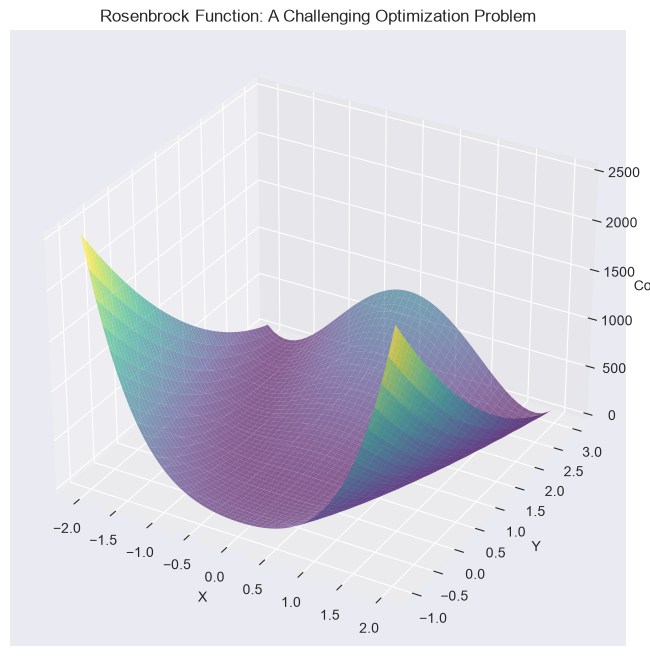

In [11]:
# Create a more complex optimization problem
def rosenbrock(x, y):
    """Rosenbrock function - classic optimization test"""
    return (1 - x)**2 + 100 * (y - x**2)**2

# Generate grid
x = np.linspace(-2, 2, 50)
y = np.linspace(-1, 3, 50)
X_grid, Y_grid = np.meshgrid(x, y)
Z = rosenbrock(X_grid, Y_grid)

# Plot the surface
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X_grid, Y_grid, Z, cmap='viridis', alpha=0.6)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Cost')
ax.set_title('Rosenbrock Function: A Challenging Optimization Problem')
plt.show()

## 8. Summary and Comparison Table

In [12]:
# Create comparison table
comparison_data = {
    'Method': ['Batch GD', 'SGD', 'Mini-Batch GD', 'Momentum', 'Adam'],
    'Update Type': ['Batch', 'Single Sample', 'Batch of Size k', 'Batch', 'Batch'],
    'Speed': ['Slow', 'Fast', 'Medium', 'Medium', 'Fast'],
    'Stability': ['High', 'Low', 'Medium', 'Medium', 'High'],
    'Memory': ['High', 'Low', 'Medium', 'Low', 'Low'],
    'Convergence': ['Smooth', 'Oscillating', 'Smoothing', 'Faster', 'Fastest'],
    'Use Case': ['Small datasets', 'Large datasets', 'Medium datasets', 'Neural nets', 'Deep learning']
}

import pandas as pd
comparison_df = pd.DataFrame(comparison_data)
print("=== Gradient Descent Variants Comparison ===")
print(comparison_df.to_string(index=False))

=== Gradient Descent Variants Comparison ===
       Method     Update Type  Speed Stability Memory Convergence        Use Case
     Batch GD           Batch   Slow      High   High      Smooth  Small datasets
          SGD   Single Sample   Fast       Low    Low Oscillating  Large datasets
Mini-Batch GD Batch of Size k Medium    Medium Medium   Smoothing Medium datasets
     Momentum           Batch Medium    Medium    Low      Faster     Neural nets
         Adam           Batch   Fast      High    Low     Fastest   Deep learning


## 9. Key Takeaways

### When to Use Each Variant:

1. **Batch Gradient Descent**:
   - Small datasets (< 1000 samples)
   - Need stable convergence
   - Convex optimization problems

2. **Stochastic Gradient Descent (SGD)**:
   - Very large datasets
   - Online learning scenarios
   - Need to escape local minima

3. **Mini-Batch Gradient Descent**:
   - Most common in practice
   - Balanced approach
   - GPU-accelerated training
   - Deep learning applications

4. **Momentum**:
   - Accelerates convergence
   - Reduces oscillations
   - Good for noisy gradients

5. **Adam**:
   - Default choice for deep learning
   - Adaptive learning rates
   - Works well for most problems
   - Minimal hyperparameter tuning

### Hyperparameter Tuning Tips:

1. **Learning Rate**:
   - Start with 0.01 or 0.001
   - Use learning rate schedulers
   - Monitor convergence

2. **Batch Size** (Mini-Batch):
   - Typical values: 32, 64, 128, 256
   - Trade-off: Larger batch = faster but more memory

3. **Momentum** (Momentum GD):
   - Typical value: 0.9
   - Higher values = more influence of previous steps

4. **Adam Hyperparameters**:
   - β₁: 0.9 (momentum)
   - β₂: 0.999 (variance)
   - ε: 1e-8 (small constant for numerical stability)

### Common Pitfalls:

1. ❌ Learning rate too large → Divergence
2. ❌ Learning rate too small → Slow convergence
3. ❌ Not standardizing features → Poor convergence
4. ❌ Not shuffling data (SGD) → Biased updates
5. ❌ Using default hyperparameters blindly